# 01 — Local-shadow Policy Preview

Apply this version's offline policy to a fixed random sample of calibration originals to inspect routing, per-image cost and before/after pixels. Nothing is exported, trained or tuned here.

**Inputs:** v2.yaml (this folder), the shared split table and original calibration images.

**Outputs:** In-memory tables and figures only.

**Prerequisites:** Original BDD sources under the shared data_root. No upstream notebook is executed.

**Outline**

- [1. Configuration](#section-1)
- [2. Policy on Calibration Samples](#section-2)
- [3. Policy Summary](#section-3)

<a id="section-1"></a>

## 1. Configuration

Change SAMPLES/SHOW freely; policy parameters live only in the version YAML.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from vehicle_detection.common import project_root, read_image, require_paths
from vehicle_detection.experiment_data import load_experiment, shared_splits
from vehicle_detection.preprocess import apply_recipe

ROOT = project_root()
os.chdir(ROOT)  # Run All behaves the same from any kernel working directory.
EXPERIMENT = "v2"
require_paths(
    config=ROOT / f"notebooks/experiments/{EXPERIMENT}/{EXPERIMENT}.yaml",
    shared=ROOT / "configs/data.yaml",
)
config = load_experiment(ROOT, EXPERIMENT)

SAMPLES = 64
SHOW = 4
shared, rows = shared_splits(ROOT)
data_root = ROOT / shared["data_root"]
require_paths(data_root=data_root)

<a id="section-2"></a>

## 2. Policy on Calibration Samples

Features are measured on the original pixels; only the routed operator changes the image.

,images,ms,brightness,contrast
applied,,,,
local_shadow,64,19.327264,0.235058,0.178598


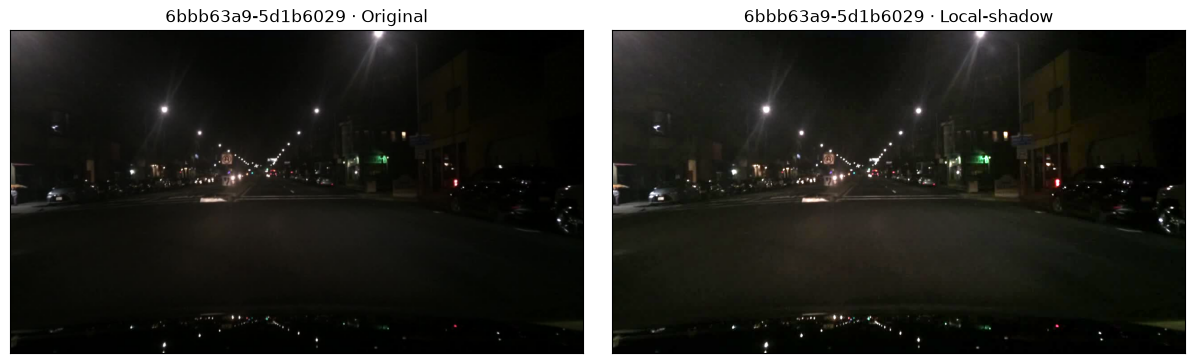

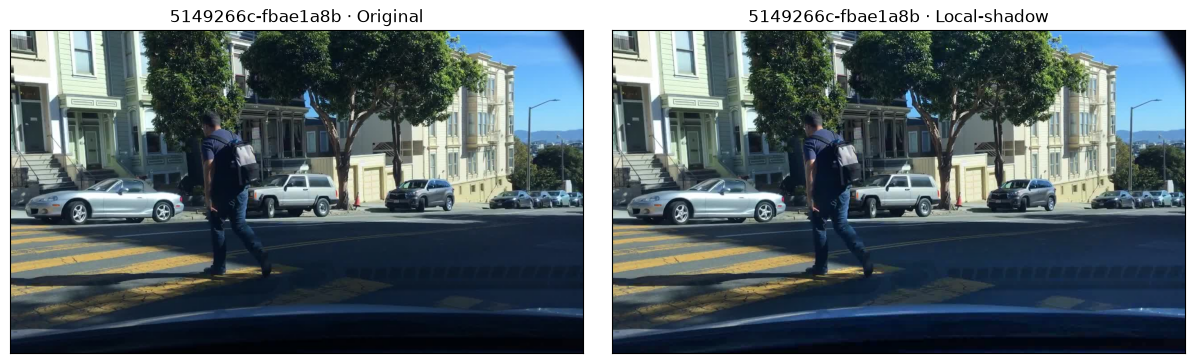

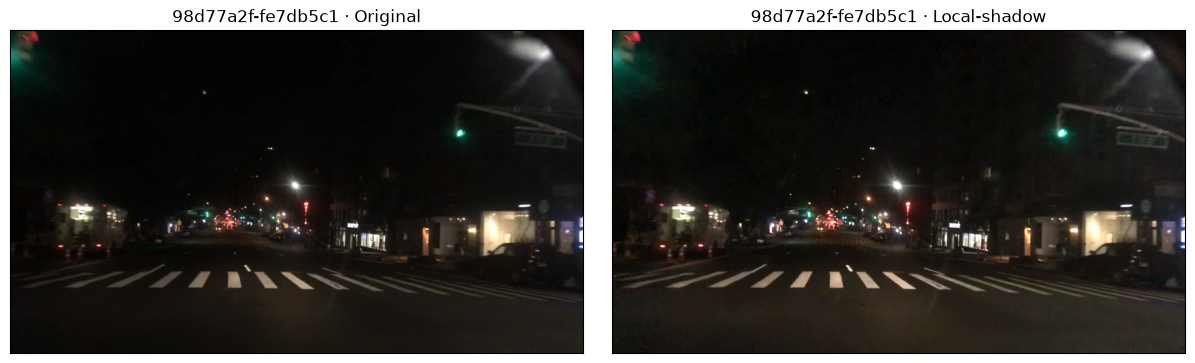

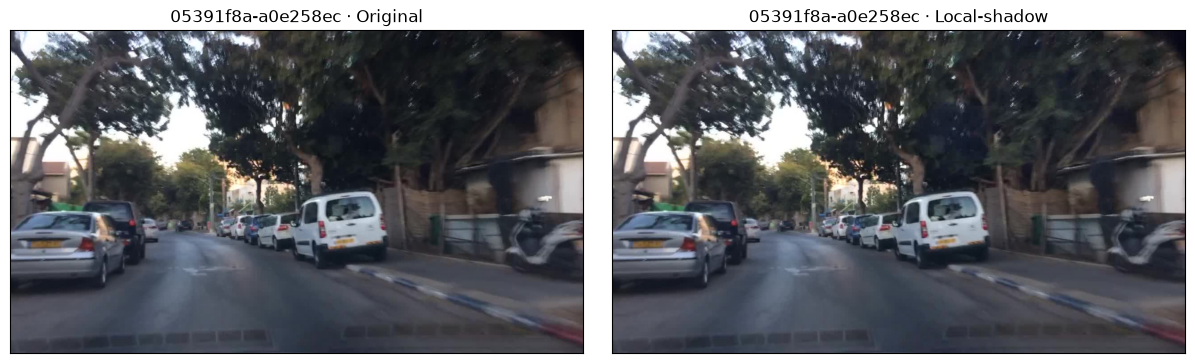

In [2]:
calibration = [r for r in rows if r["role"] == "calibration"]
picked = np.random.default_rng(config["seed"]).choice(len(calibration), SAMPLES, replace=False)
records, pairs = [], []
for index in picked:
    row = calibration[index]
    image = read_image(data_root / row["source_path"])
    start = time.perf_counter()
    output, applied, scores = apply_recipe(image, config["variant"], config["recipes"])
    elapsed = (time.perf_counter() - start) * 1000
    records.append(
        {"id": row["id"], "applied": "+".join(a["name"] for a in applied), "ms": elapsed, **scores}
    )
    if applied and len(pairs) < SHOW:
        pairs.append((row["id"], image, output))
preview = pd.DataFrame(records)
display(
    preview.groupby("applied", dropna=False).agg(
        images=("id", "size"),
        ms=("ms", "mean"),
        brightness=("brightness", "mean"),
        contrast=("contrast", "mean"),
    )
)
for sample_id, before, after in pairs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
    for ax, image, label in zip(axes, (before, after), ("Original", config["name"]), strict=True):
        ax.imshow(image[:, :, ::-1])
        ax.set(title=f"{sample_id} · {label}", xticks=[], yticks=[])
    plt.show()

<a id="section-3"></a>

## 3. Policy Summary

In [3]:
print("Variant:", config["variant"], "| Recipes:", config["recipes"])
print(f"Applied to {(preview.applied != '').mean():.1%} of {len(preview)} calibration samples")
print("Export happens only in 02_train_prepare; final-test pixels stay sealed.")

Variant: local_shadow | Recipes: {'local_shadow': {}}
Applied to 100.0% of 64 calibration samples
Export happens only in 02_train_prepare; final-test pixels stay sealed.


## Historical experiment lineage — v2

This notebook retains **all current preprocessing preview cells and their saved outputs**, while adding research experiment provenance from the pre-PR #55 repository. The historical protocols remain distinguishable from S20 full-finetuning and new cross-evaluation. Historical/failed-pilot claims cannot become new independent evidence. The final holdout is sealed, and no evaluation or training has been rerun.

Current training and native evaluation remain in `02_train_prepare`, `03_train`, `04_eval`; cross-policy comparison remains in `../compare.ipynb`. The archive below contains full historical Python procedure text but does **not** execute removed modules.

### Embedded historical results (readable without Git or external JSON)

Snapshot: `948e1d3fd5d7f1f745121fb1ad5063076a682884` (pre-PR #55). The 15 historical registry JSON files are absent from the current tree; the summaries below were transcribed from that pinned snapshot and its named reports. Percentages are AP50:95 unless stated; differences are percentage points (pp). No historical inference/training was rerun for this restoration. The final holdout remains sealed.

**Naming boundary:** historical “frozen v2” means Issue #6’s `issue6-policy-v2` Gamma-or-Skip; it is not today’s local-shadow `v2`. Historical frozen-backbone experiments are separate from current full fine-tuning.

#### v2-screening — Round2 preprocessing screening

Twenty treatments across ten clean/synthetic scenarios used matched five-class inputs. Denoise 5 led exploration at family-balanced AP50:95 18.8825% versus historical frozen Gamma-or-Skip 18.2237% and Skip 18.2089%. On disjoint 260-image confirmation, it fell to 16.2714% versus 16.8230% / 16.7337%: -0.5516 / -0.4623 points. Clean, scenario and class regression limits also failed. Status: `confirmation_failed`, no policy selected or v3 released; the development transfer was descriptive with no retuning. All 260 evaluations / 66,680 image passes are historical pretrained evidence, not new fine-tuning or final-test results.

Provenance: [docs/round2-preprocessing-v2/summary.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/round2-preprocessing-v2/summary.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/ISSUE30_RESULTS.md). JSON SHA256: `d77ee8d546d272ff9e67c7fef668d68e2b5a80b23362f3f23a4013d062afa054`.

#### v2-quality — Quality/cost review

Thirty additional exploration evaluations (7,680 image passes) measured Gamma 0.775, Sharpen 0.075 and Sharpen-to-Bilateral: family-balanced AP50:95 17.5372%, 18.1824%, 18.3198%; none entered the leading route. The directly timed leader averaged 4.38 ms, with worst-scenario mean 5.06 ms and p95 7.73 ms, passing the 10/25 ms gates. All six recorded direct-cost gates passed, but status remained `pending_fresh_confirmation`; confirmation was metadata-only, no predictions, and no v3 released. Exploration search and feasible cost do not establish a confirmed accuracy gain.

Provenance: [docs/round2-quality-v2/summary.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/round2-quality-v2/summary.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/ISSUE30_QUALITY_REVIEW.md). JSON SHA256: `c4117c30b0e9f062d9cdffc638e1eb71ba28693dbaed186180e1dfbbbeef3072`.

#### v2-replication — Round3 sentinel replication

The five-scenario sentinel on the new 256 exploration images gave family-balanced AP50:95: Skip 13.54089%, historical frozen Gamma-or-Skip 13.60626%, PR #38 route 13.59006%, bilateral 13.41345%, noise-range bilateral 13.54876%. The route advantage over the frozen control changed from +0.59575 points on old images to -0.01621 on new images (conditional 95% interval [-0.24858, +0.32628]). After 25 evaluations / 12,800 image passes, every treatment failed the +0.2-point improvement gate despite passing cost/regression limits; the remaining 25 evaluations were not run. Status: `exploration_only_retain_frozen_v2`; stop this direction, no v3 or confirmation consumption.

Provenance: [docs/round2-research-v3/summary.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/round2-research-v3/summary.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/ISSUE30_RESEARCH_ROUND3.md). JSON SHA256: `91b67aa24c4923dfa76f40f0308a9cac5c6ac7cb43a639f5bb77542b15bb1173`.

#### v2-pilot — Issue #45 pretrained local-shadow pilot

On 256 natural calibration-exploration images / 136 groups, AP50:95 was Raw 15.7103%, Gamma-or-Skip 15.7223%, local-shadow 15.8248%. The +0.1145 / +0.1026-point gains missed the +0.2 gate. Local-shadow versus Raw had conditional 95% interval [-0.5926, +0.6592]; dark-car AP lost 1.0285 points, and five-class dark support was insufficient. Mean/p95 preprocessing was 11.117/12.410 ms, failing the 10 ms mean limit. `advance=False`, no pilot training or confirmation. The declaration was hash-bound before inference but not separately committed. These failed gates stay failed after later training.

Provenance: [docs/issue45/summary.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/issue45/summary.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/ISSUE45_RESULTS.md). JSON SHA256: `dcc5d59a193098a1cfa28efa1dd1ed39bec9d68079c43438327f383500edef4f`.

#### v2-s20-followup — Separate matched S20 follow-up

A separately declared experiment trained 9,781 S20 images for 20 epochs at 640, FP32 AdamW, frozen backbone 11, one seed; 13,975 Raw development images selected checkpoints. Policy-matched development AP50:95 was v0 20.6124%, v1 20.6879%, local-shadow v2 20.4930% (-0.1194 / -0.1949 points). Local-shadow preprocessing mean/p95 was 13.627/16.382 ms. Completion is not promotion: the primary metric lost to both controls, with mixed class/subgroup effects and no independent confirmation. Plan/config were committed before execution at `f1661c4`; the original failed pretrained pilot is unchanged. This is historical frozen-backbone training, not current full fine-tuning.

Provenance: [docs/issue45-s20/summary.json](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/issue45-s20/summary.json); [historical report](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/docs/ISSUE45_S20_EXECUTION.md). JSON SHA256: `ef97c6a61c50a4520ee8b1f376bb9cfc3a686e8e7001ad7f18a05a57590d23bf`.



## A. Study registry and saved evidence

Run the next cell to see each study, its dataset/population, archival evidence path and interpretation boundary. For detailed saved JSON evidence, run `inspect_saved_study("study-id")` manually. Historical git history is read-only. Missing evidence is reported as unavailable, not re-created or misreported as zero.

In [ ]:
# Historical experiment ledger — no training, inference or file writes
import json
import subprocess

import pandas as pd
from IPython.display import display

HISTORICAL_COMMIT = "948e1d3fd5d7f1f745121fb1ad5063076a682884"
RESEARCH_ROOT = ROOT  # Reuse the preview configuration and its prerequisite checks.
STUDIES = [
    {
        "id": "v2-screening",
        "provenance": "historical screening",
        "population": "Round2 preprocessing search",
        "evidence": "docs/round2-preprocessing-v2/summary.json",
        "boundary": "Screening is not confirmation",
    },
    {
        "id": "v2-quality",
        "provenance": "historical quality",
        "population": "Quality/cost assessment",
        "evidence": "docs/round2-quality-v2/summary.json",
        "boundary": "Not native AP",
    },
    {
        "id": "v2-replication",
        "provenance": "historical replication",
        "population": "Research round 3",
        "evidence": "docs/round2-research-v3/summary.json",
        "boundary": "Not newly trained model",
    },
    {
        "id": "v2-pilot",
        "provenance": "historical native pilot",
        "population": "Issue45 local-shadow pretrained",
        "evidence": "docs/issue45/summary.json",
        "boundary": "Original failure gate remains failed",
    },
    {
        "id": "v2-s20-followup",
        "provenance": "historical S20 follow-up",
        "population": "Issue45 matched detector",
        "evidence": "docs/issue45-s20/summary.json",
        "boundary": "Cannot retrospectively pass pilot",
    },
    {
        "id": "v2-current",
        "provenance": "current full-finetune",
        "population": "S20; YOLO26n full-finetune",
        "evidence": "notebooks/experiments/v2/04_eval.ipynb",
        "boundary": "Use current 02–04 lifecycle",
    },
]

display(
    pd.DataFrame(STUDIES).rename(
        columns={
            "id": "Study",
            "provenance": "Source",
            "population": "Population / design",
            "evidence": "Evidence file",
            "boundary": "Interpretation",
        }
    )
)


def archived_evidence(path):
    """Historical snapshot first; local copy only as a provenance-labelled fallback."""
    try:
        proc = subprocess.run(
            ["git", "-C", str(RESEARCH_ROOT), "show", f"{HISTORICAL_COMMIT}:{path}"],
            capture_output=True,
            check=False,
            timeout=20,
        )
        if proc.returncode == 0:
            return proc.stdout, f"commit {HISTORICAL_COMMIT[:12]}"
    except (OSError, subprocess.TimeoutExpired):
        pass
    local = RESEARCH_ROOT / path
    if local.is_file():
        return local.read_bytes(), "local file: verify revision"
    return None, "not available in local checkout"


def inspect_saved_study(study_id):
    """Display recorded evidence; never rerun acquisition or invent absent metrics."""
    s = next((item for item in STUDIES if item["id"] == study_id), None)
    if s is None:
        raise ValueError(f"Unknown study: {study_id}")
    print("Study:", s["id"], "|", s["population"])
    print("Boundary:", s["boundary"])
    path = s["evidence"]
    if path.endswith(".ipynb"):
        print("Active lifecycle notebook:", path)
        return
    raw, origin = archived_evidence(path)
    print("Evidence:", path, "|", origin)
    if raw is None:
        print("Missing saved evidence is NOT a zero metric or a failed study.")
        return
    if path.endswith(".json"):
        report = json.loads(raw.decode("utf-8"))
        if isinstance(report, dict):
            print("Saved fields:", list(report))
        display(report)
    elif path.endswith(".csv"):
        from io import BytesIO

        display(pd.read_csv(BytesIO(raw)).head(30))
    else:
        print(raw.decode("utf-8", errors="replace")[:12000])


# Inspect on demand, e.g. inspect_saved_study("v2-pilot")

## B. Archived full experiment procedures

Original notebook markdown and Python source are preserved in the following non-executable appendix. Source code may reference modules and evidence removed by PR #55; code is intentionally quoted rather than run. 

### 1. 01_experiments.ipynb

**Historical study — non-executable source archive.** [Original notebook at pinned pre-refactor commit](https://github.com/truong51972/vehicle-detection/blob/948e1d3fd5d7f1f745121fb1ad5063076a682884/notebooks/experiments/v2/01_experiments.ipynb). Original procedure, code, acquisition flags, cohorts, uncertainty and interpretation are reproduced below; old dependencies removed in PR #55 are **not imported or executed**.

**Original cell 1 — study narrative**

#### 01 — Later Preprocessing Exploration

Review historical failed gates and run the separately declared issue #45 local-shadow pilot. v2 identifies this exploratory study; no replacement policy is locked.

**Inputs:** Preserved round2 evidence; docs/ISSUE45_PILOT.md; original calibration sources and pinned weights only for an opted-in pilot.

**Outputs:** Read-only historical/pilot evidence by default; opted-in native pilot outputs at runs/issue45/pilot and compact evidence at docs/issue45.

**Prerequisites:** Committed research results. New inference additionally needs the local study environment, original BDD sources and weights/yolo26n.pt. No upstream notebooks execute.

**Outline**

- [1. Configuration](#section-1)
- [2. Observed Decisions](#section-2)
- [3. Exploration Summary](#section-3)

**Original cell 2 — study narrative**

##### 1. Configuration

Saved failed-pilot evidence is the default. ALLOW_PILOT=True is an explicit historical-pilot opt-in; existing outputs cannot be overwritten and future attempts now require adequate dark class support before inference. Use the separate 02/03/04 notebooks for the committed exploratory S20 extension.

**Original cell 3 — Python source (archived, not run)**

```python
from pathlib import Path

from IPython.display import display

from vehicle_detection.common import read_json, require_paths

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
REPORTS = {
    "screening": ROOT / "docs/round2-preprocessing-v2/summary.json",
    "quality": ROOT / "docs/round2-quality-v2/summary.json",
    "replication": ROOT / "docs/round2-research-v3/summary.json",
}
require_paths(**REPORTS)

ALLOW_PILOT = False
```

**Original cell 4 — study narrative**

##### 2. Observed Decisions

All measurements retain their original paths, parameters, populations and attribution. None is a newly trained v2 detector.

**Original cell 5 — Python source (archived, not run)**

```python
for name, path in REPORTS.items():
    print(name, path.relative_to(ROOT))
    display(read_json(path))
```

**Original cell 6 — study narrative**

##### 3. Exploration Summary

The original pilot decision remains failed. Its v2_trained flag records that historical stage. The separately committed post-pilot hypothesis tests matched S20 fine-tuning without retuning the recipe or changing any pilot gate.

**Original cell 7 — Python source (archived, not run)**

```python
from vehicle_detection.v2_pilot import run

if ALLOW_PILOT or (ROOT / "docs/issue45/summary.json").exists():
    pilot = run(ROOT, allow_inference=ALLOW_PILOT)
    display(pilot["decision"])
    display(pilot["native"])
    display(pilot["runtime"])
else:
    print("Issue #45 pilot has not executed; see docs/ISSUE45_PILOT.md.")
print("The flags above describe the historical pretrained pilot, not the current S20 lifecycle.")
if (ROOT / "docs/issue45-s20/v2_metrics.json").exists():
    saved = read_json(ROOT / "docs/issue45-s20/v2_metrics.json")
    print("Separate exploratory S20 train/eval completed; pretrained gates remain failed.")
    display(saved["overall"])
else:
    print("S20 extension plan: docs/ISSUE45_FINETUNING_PLAN.md; execution is separate in 02/03/04.")
print("Final holdout stays sealed; no confirmed/released replacement policy is claimed.")
```



### Current lifecycle boundary

The original seven preview cells remain first, unchanged from `main`, including source, saved outputs and execution metadata. Current S20 preparation, training and native evaluation belong in `02_train_prepare`, `03_train` and `04_eval`; cross-policy comparisons belong in `../compare.ipynb`. Historical results above do not validate the current full-finetune recipe.